In [2]:
#Importamos las librerías que vamos a utilizar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML
from scipy.stats import skew, kurtosis

In [3]:
ruta = r"Material/Datasets/ai4i2020.csv"
df = pd.read_csv(ruta)

In [4]:
# Mostramos la cantidad de filas y columnas del DataFrame
print("El DataFrame tiene", df.shape[0], "filas y", df.shape[1] ,"columnas")

El DataFrame tiene 10000 filas y 14 columnas


In [5]:
# Mostramos las primeras filas del DataFrame
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
# Creamos un nuevo DataFrame para juntar informaciones
info_df = pd.DataFrame({
    'Tipo de Dato': df.dtypes,
    'Valores Nulos': df.isnull().sum(),
})

# Asignamos un nombre a la primera columna del DataFrame
info_df = info_df.reset_index().rename(columns={'index': 'Variables'})

info_df

,Variables,Tipo de Dato,Valores Nulos
0,UDI,int64,0
1,Product ID,object,0
2,Type,object,0
3,Air temperature [K],float64,0
4,Process temperature [K],float64,0
5,Rotational speed [rpm],int64,0
6,Torque [Nm],float64,0
7,Tool wear [min],int64,0
8,Machine failure,int64,0
9,TWF,int64,0


In [7]:
# Generamos las estadísticas descriptivas del DataFrame
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### 🔍 Diagnóstico del Balance de Clases 


In [38]:
# Vamos a ver la cantidad de fallas que hay en el dataset
conteo_fallas = df['Machine failure'].value_counts()

# Calculamos el porcentaje de fallas en el dataset
porcentaje_fallas = df['Machine failure'].value_counts(normalize=True) * 100

# Resumen 
resumen_fallas = pd.DataFrame({
    'Cantidad de fallas' : conteo_fallas,
    'Porcentaje (%)' : porcentaje_fallas.round(4)
})

resumen_fallas.index.name = None

resumen_fallas

,Cantidad de fallas,Porcentaje (%)
0,9661,96.61
1,339,3.39


A partir del análisis cuantitativo de la variable objetivo `Machine failure`, se extraen las siguientes conclusiones analíticas fundamentales para el desarrollo del modelo:

* **Predominancia de la Clase Mayoritaria:** El **96.61%** de los registros históricos corresponden a un estado operativo normal (Clase `0`), sumando un total de **9,661 observaciones**.
* **Presencia de la Clase Minoritaria (Target):** Se registraron únicamente **339 eventos de falla mecánica** (Clase `1`), lo que equivale al **3.39%** del conjunto de datos total.

### 🛠️ Análisis Desagregado de Tipos de Falla


In [9]:
# Creamos una lista con las columnas de fallas específicas
columnas_fallas = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

# Sumamos los valores de cada columna
conteo_fallas_especificas = df[columnas_fallas].sum()

# Creamos un DataFrame y lo ordenamos de mayor a menor
tabla_fallas_especificas = pd.DataFrame({
    'Total de Eventos': conteo_fallas_especificas,
}).sort_values(by='Total de Eventos', ascending=False)

# Quitamos el nombre del índice para que quede más limpio
tabla_fallas_especificas.index.name = None

# Calculamos la suma total de eventos y lo agregamos a la tabla
tabla_fallas_especificas.loc['Total'] = tabla_fallas_especificas.sum()

tabla_fallas_especificas

,Total de Eventos
HDF,115
OSF,98
PWF,95
TWF,46
RNF,19
Total,373


Para entender la naturaleza del desbalance, se aislaron y contabilizaron de forma independiente los modos de falla registrados por los sensores:

* **HDF (Heat Dissipation Failure - 115 eventos):** Es la causa principal de avería. Indica problemas críticos de disipación térmica y sobrecalentamiento en la operación.
* **OSF (Overstrain Failure - 98 eventos):** El segundo factor de riesgo, asociado a tensiones mecánicas excesivas o sobreesfuerzos estructurales.
* **PWF (Power Failure - 95 eventos):** Fallos directamente relacionados con fluctuaciones o pérdidas en el suministro de potencia eléctrica.
* **TWF (Tool Wear Failure - 45 eventos):** Desgaste acumulado de la herramienta de corte que alcanza su límite seguro.
* **RNF (Random Failure - 18 eventos):** Eventos de fallo aleatorios no correlacionados directamente con los sensores principales.
<br>
<br>
> 💡 **Nota de Consistencia de Datos:** Si sumamos todos estos eventos individuales obtenemos 373 fallas, lo cual supera las 339 fallas registradas identificadas con 'Machine failure = 1'. Este hallazgo es clave para nuestro análisis EDA: **existen ciclos de operación específicos donde la máquina sufrió múltiples modos de falla simultáneos** durante el mecanizado de una pieza.



### Análisis de fallas simultáneas

In [10]:
fallas_multiples = df[df[columnas_fallas].sum(axis=1) >= 2].copy()

# Agregamos una columna que nos indique que fallas ocurrieron a la misma vez
fallas_multiples['Fallas simultáneas'] = fallas_multiples[columnas_fallas].apply(
    lambda fila: ', '.join([col for col in columnas_fallas if fila[col] == 1]),
    axis = 1
)

tabla_fallas_multiples = fallas_multiples [['Machine failure', 'Fallas simultáneas']].reset_index()
tabla_fallas_multiples.columns = ['ID ciclo', 'Alarma general', 'Modos de fallas detectados']

tabla_render = tabla_fallas_multiples.set_index('ID ciclo')

# Mostramos la cantidad total abajo
print(f"Total de registros con fallas simultáneas: {len(tabla_fallas_multiples)}")


Total de registros con fallas simultáneas: 24


Al cruzar los datos globales con las etiquetas específicas, la matemática nos arroja una diferencia neta de **34 fallas** ($373 - 339 = 34$). Sin embargo, el filtro de registros con fallas simultáneas solo detecta **24 ciclos**. 

Entonces, **Qué pasó acá??**, empecemos a investigar que pasa con esos diez datos faltantes.

In [34]:
# Filtramos el DataFrame, cuando Machine failure = 0 y alguna columna de fallo es = 1
dataset_filtrado_1 = df[(df['Machine failure'] == 0) & (df[columnas_fallas].sum(axis=1) == 1)]
dataset_filtrado_1_1 = df[(df['Machine failure'] == 1) & (df['RNF'] == 1)]

display(dataset_filtrado_1)
display(dataset_filtrado_1_1)

# Realizamos el conteo de filas
print('Hay un total de:', len(dataset_filtrado_1)+len(dataset_filtrado_1_1), 'registros donde Machine failura = 0 y RNF = 1')

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,M16081,M,297.0,308.3,1399,46.4,132,0,0,0,0,0,1
1302,1303,L48482,L,298.6,309.8,1505,45.7,144,0,0,0,0,0,1
1748,1749,H31162,H,298.4,307.7,1626,31.1,166,0,0,0,0,0,1
2072,2073,L49252,L,299.6,309.5,1570,35.5,189,0,0,0,0,0,1
2559,2560,L49739,L,299.3,309.0,1447,50.4,140,0,0,0,0,0,1
3065,3066,M17925,M,300.1,309.2,1687,27.7,95,0,0,0,0,0,1
3452,3453,H32866,H,301.6,310.5,1602,32.3,2,0,0,0,0,0,1
5471,5472,L52651,L,302.7,312.3,1346,61.2,170,0,0,0,0,0,1
5489,5490,L52669,L,302.6,312.1,1499,35.0,215,0,0,0,0,0,1
5495,5496,H34909,H,302.9,312.5,1357,55.0,12,0,0,0,0,0,1


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
3611,3612,L50791,L,301.7,310.9,1405,46.4,207,1,1,0,0,0,1


Hay un total de: 19 registros donde Machine failura = 0 y RNF = 1


In [29]:
dataset_filtrado_2 = df[(df['Machine failure'] == 1) & (df[columnas_fallas].sum(axis=1) == 0)]
display(dataset_filtrado_2)

# Realizamos el conteo de filas
print('Hay un total de:', len(dataset_filtrado_2), 'registros donde Machine failura = 1 y [TWF, HDF, PWF, OSF] = 0')

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
1437,1438,H30851,H,298.8,309.9,1439,45.2,40,1,0,0,0,0,0
2749,2750,M17609,M,299.7,309.2,1685,28.9,179,1,0,0,0,0,0
4044,4045,M18904,M,301.9,310.9,1419,47.7,20,1,0,0,0,0,0
4684,4685,M19544,M,303.6,311.8,1421,44.8,101,1,0,0,0,0,0
5536,5537,M20396,M,302.3,311.8,1363,54.0,119,1,0,0,0,0,0
5941,5942,L53121,L,300.6,310.7,1438,48.5,78,1,0,0,0,0,0
6478,6479,L53658,L,300.5,309.8,1663,29.1,145,1,0,0,0,0,0
8506,8507,L55686,L,298.4,309.6,1710,27.3,163,1,0,0,0,0,0
9015,9016,L56195,L,297.2,308.1,1431,49.7,210,1,0,0,0,0,0


Hay un total de: 9 registros donde Machine failura = 1 y [TWF, HDF, PWF, OSF] = 0


### Análisis de Discrepancias en los Registros de Falla

Al comparar la variable objetivo principal (`Machine failure`) con las columnas de fallas específicas (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`), se observa una inconsistencia numérica. Mientras que el sistema registra **339** paradas de máquina generales, la suma individual de las alarmas específicas asciende a **373**. 

Esta diferencia neta de **34 eventos** (373 - 339) es el resultado de tres comportamientos operativos y de recolección de datos dentro del dataset:

#### 1. Fallas Simultáneas (+24 en fallas específicas)
Se identificaron **24 ciclos de trabajo** donde la máquina experimentó dos modos de falla al mismo tiempo (por ejemplo, un pico de sobreesfuerzo mecánico que deriva en un problema de disipación de calor).

#### 2. Fallas Aleatorias u Ocultas (+19 en fallas específicas)
Existen **19 registros** clasificados como fallas aleatorias (`RNF` = 1) donde la alarma general de la máquina nunca se activó (`Machine failure` = 0).
* **Impacto en los datos:** Al estar presentes en las causas específicas pero no sumar al conteo general, generan un excedente de **+19**.
* **Significado analítico:** La documentación técnica del dataset define las `RNF` como simulaciones de eventos ajenos al proceso de mecanizado (ej. caídas de tensión eléctrica o errores de hardware). Representan ruido estocástico que no responde a la termodinámica ni a la cinemática del equipo.

#### 3. Fallas Fantasma (-9 en fallas específicas)
Se detectaron **9 casos** donde la máquina registró una parada general (`Machine failure` = 1), pero todos los sensores de fallas específicas (incluyendo las aleatorias) marcaron 0.
* **Impacto en los datos:** Suman 9 eventos al recuento general sin aportar ninguna causa específica, lo que resta **-9** a la diferencia neta.
* **Significado analítico:** En un entorno industrial, esto equivale a una falsa alarma del panel de control o a una parada por un factor no medido en la telemetría actual. 

#### Balance Final de la Discrepancia
La diferencia matemática queda perfectamente cerrada al cruzar estos tres fenómenos en el dataset:

* **+ 24** (Fallas múltiples que duplican la causa específica)
* **+ 19** (Fallas aleatorias no registradas en la alarma general)
* **- 9** (Falsas alarmas sin causa registrada)
* **= 34** (Diferencia exacta entre las 373 causas específicas y las 339 paradas generales).

### Visualización de Datos

1. Análisis descriptivo univariado. Seleccionamos las variables numéricas `Air Temperature [K]`, `Process Temperature [K]`, `Rotational Speed [rpm]`, `Torque [Nm]`, `Tool Wear [min]` para analizar asimetría y curtosis

In [4]:
# Primero identificamos los tipos de cada variable
df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [9]:
# Nos quedamos únicamente con las variables físicas
variables_fisicas = [
    'Air temperature [K]', 
    'Process temperature [K]', 
    'Rotational speed [rpm]', 
    'Torque [Nm]', 
    'Tool wear [min]'
]
df[variables_fisicas]

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,298.1,308.6,1551,42.8,0
1,298.2,308.7,1408,46.3,3
2,298.1,308.5,1498,49.4,5
3,298.2,308.6,1433,39.5,7
4,298.2,308.7,1408,40.0,9
...,...,...,...,...,...
9995,298.8,308.4,1604,29.5,14
9996,298.9,308.4,1632,31.8,17
9997,299.0,308.6,1645,33.4,22
9998,299.0,308.7,1408,48.5,25


Vemos en la siguiente celda el resultado de calcular la asimetría y la curtosis. La única variable que muestra una asimetría más marcada es `Rotational Speed [rpm]`. Los valores altos de curtosis indican una distribución estirada, con colas muy anchas y valores extremos.

In [10]:
print(f"Asimetría de las variables: \n{df[variables_fisicas].skew()}\n")
print(f"Curtosis de las variables: \n{df[variables_fisicas].kurtosis()}")

Asimetría de las variables: 
Air temperature [K]        0.114274
Process temperature [K]    0.015027
Rotational speed [rpm]     1.993171
Torque [Nm]               -0.009517
Tool wear [min]            0.027292
dtype: float64

Curtosis de las variables: 
Air temperature [K]       -0.835962
Process temperature [K]   -0.499734
Rotational speed [rpm]     7.392945
Torque [Nm]               -0.013241
Tool wear [min]           -1.166737
dtype: float64


2. Distribución de las variables

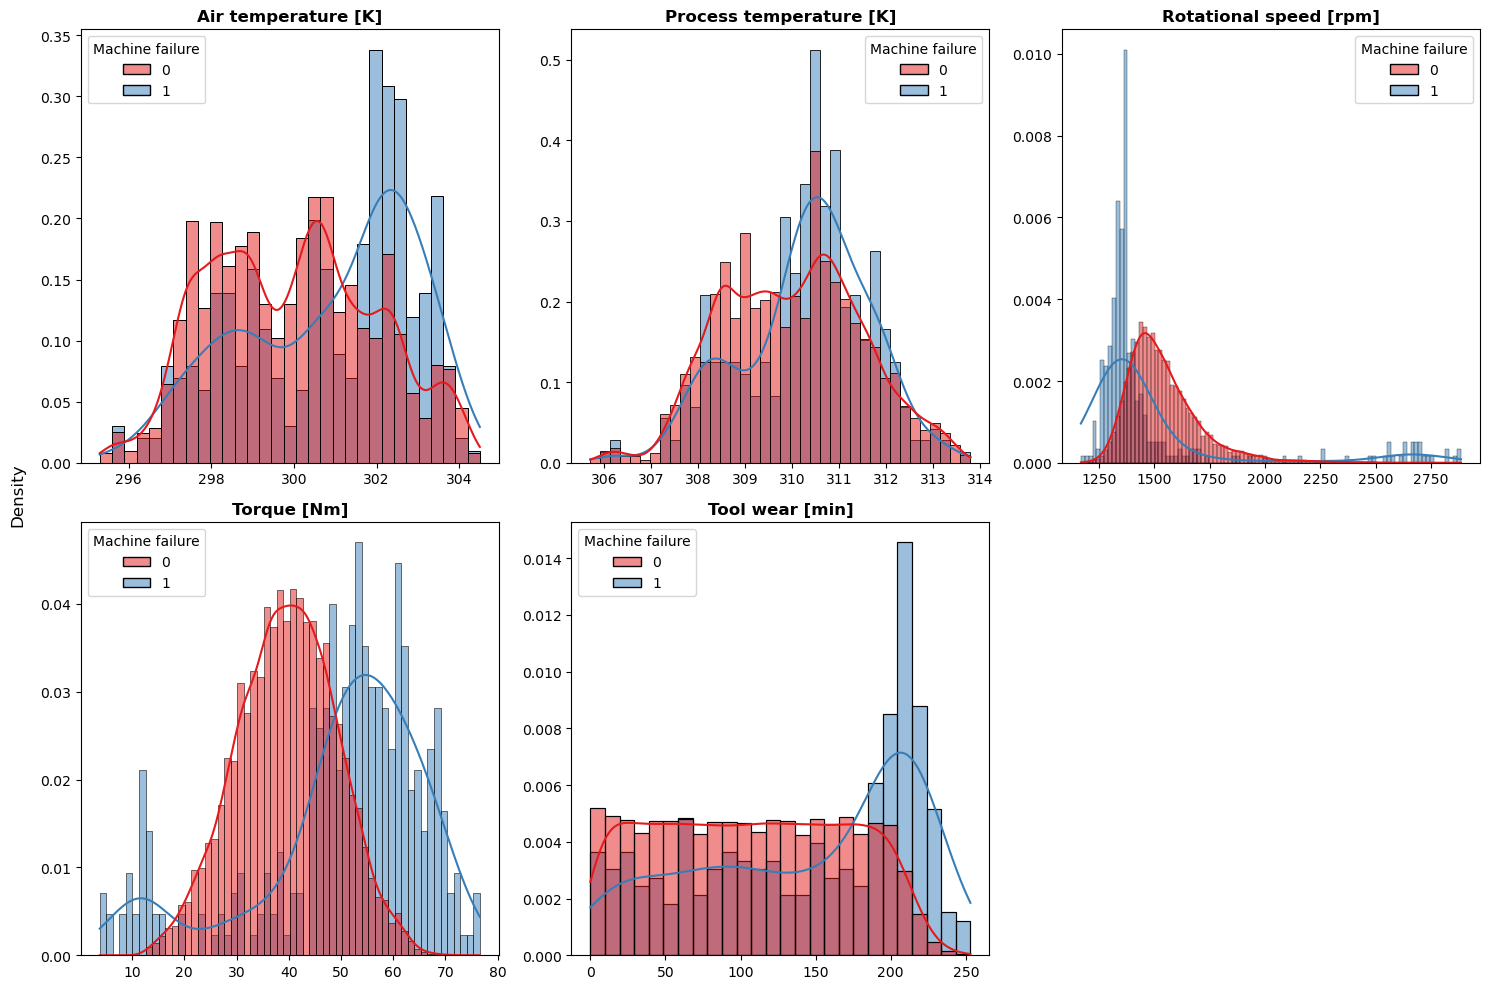

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(variables_fisicas):
    sns.histplot(
        data=df, 
        x=col, 
        hue='Machine failure', 
        kde=True, 
        stat='density',
        common_norm=False,
        palette='Set1',
        alpha=0.5,
        ax=axes[i]
    )
    
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

axes[5].axis('off')
fig.supylabel('Density', x=0.01)

plt.tight_layout()
plt.show()

3. Boxplot de las variables

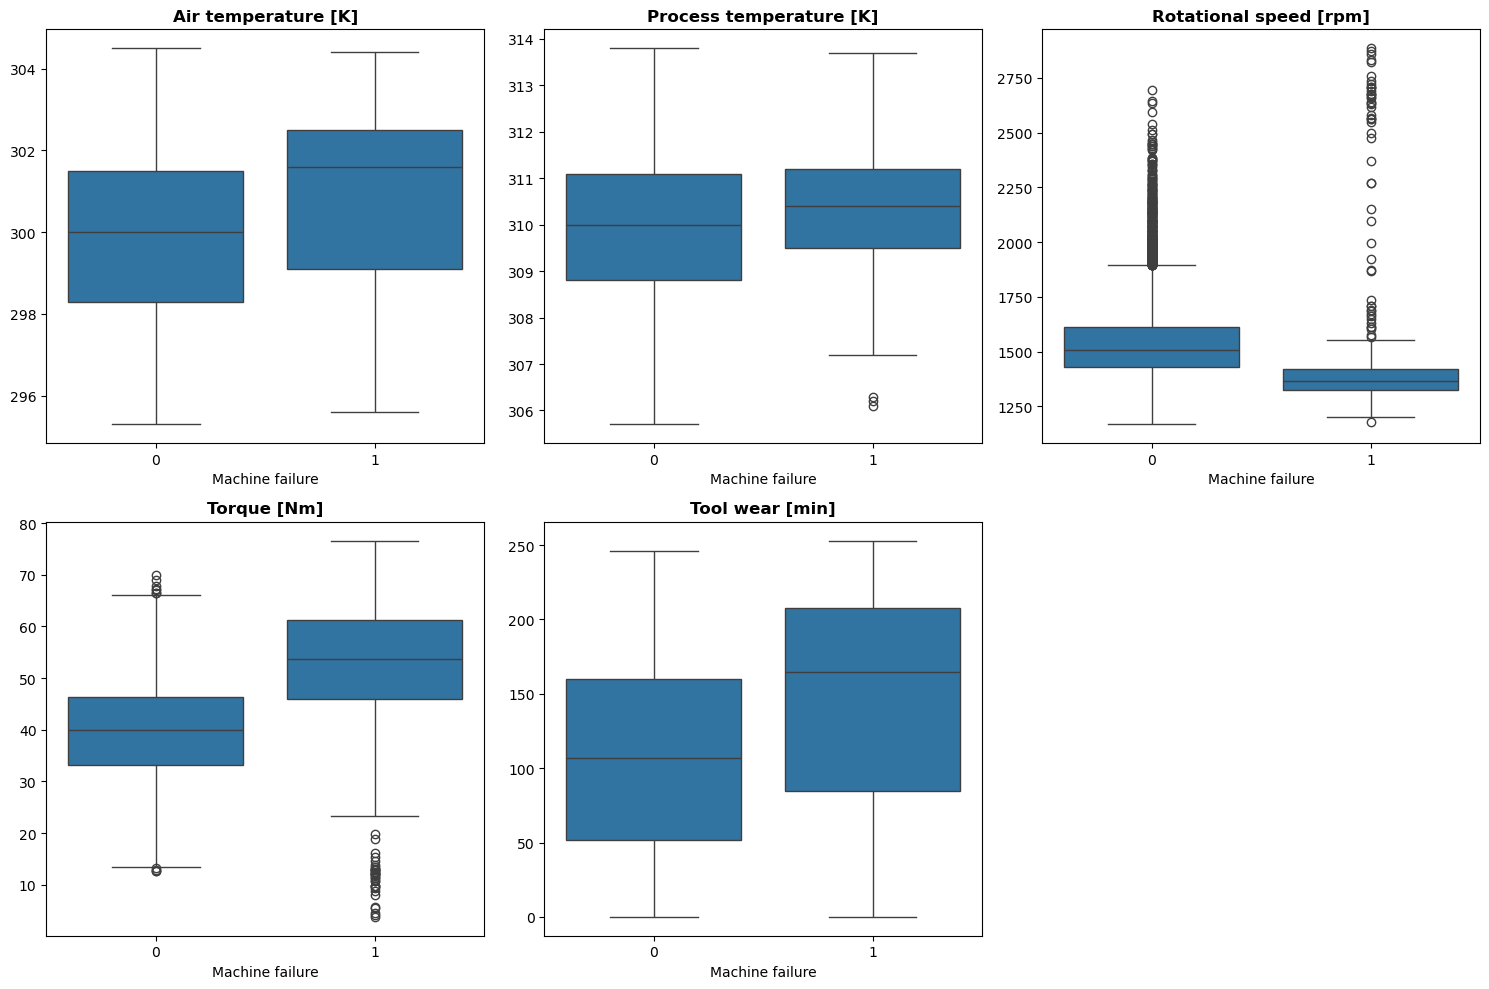

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(variables_fisicas):
    sns.boxplot(
        data=df, 
        x='Machine failure', 
        y=col, 
        ax=axes[i]
    )

    axes[i].set_title(col, fontweight='bold')
    axes[i].set_ylabel('')

axes[5].axis('off')

plt.tight_layout()
plt.show()

Observamos tanto en los histogramas como en los boxplot, que la distribución de variables es distinta en los casos que falló la máquina. Se observa una temperatura más alta, al igual que un torque y un tiempo de uso de herramienta mayor, a su vez que la velocidad rotacional disminuye significativamente. Esta variación en las distribuciones serán las que nos servirán para entrenar a nuestro modelo predictivo